# **Reconnaissance des émotions faciales**

In [1]:
import zipfile
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from tensorflow.keras import Model, layers
from sklearn.metrics import (
    classification_report,
    accuracy_score,
    f1_score
)

In [2]:
chemin_zip = "archive(1).zip" # Remplacez par le nom exact de votre zip
dossier_destination = "images_extraites"

with zipfile.ZipFile(chemin_zip, 'r') as zip_ref:
    zip_ref.extractall(dossier_destination)

print("Extraction terminée !")


Extraction terminée !


## Vérification des données

In [3]:
print(os.listdir('images_extraites'))

['test', 'train']


In [4]:
for root, dirs, files_list in os.walk('images_extraites'):
    level = root.replace('images_extraites', '').count(os.sep)

    if level <= 2:
        print("  " * level + os.path.basename(root) + "/")

        if level == 2:
            print("  " * (level + 1),
                  "Nombre d'images :", len(files_list))


images_extraites/
  test/
    angry/
       Nombre d'images : 958
    disgust/
       Nombre d'images : 111
    fear/
       Nombre d'images : 1024
    happy/
       Nombre d'images : 1774
    neutral/
       Nombre d'images : 1233
    sad/
       Nombre d'images : 1247
    surprise/
       Nombre d'images : 831
  train/
    angry/
       Nombre d'images : 3995
    disgust/
       Nombre d'images : 436
    fear/
       Nombre d'images : 4097
    happy/
       Nombre d'images : 7215
    neutral/
       Nombre d'images : 4965
    sad/
       Nombre d'images : 4830
    surprise/
       Nombre d'images : 3171


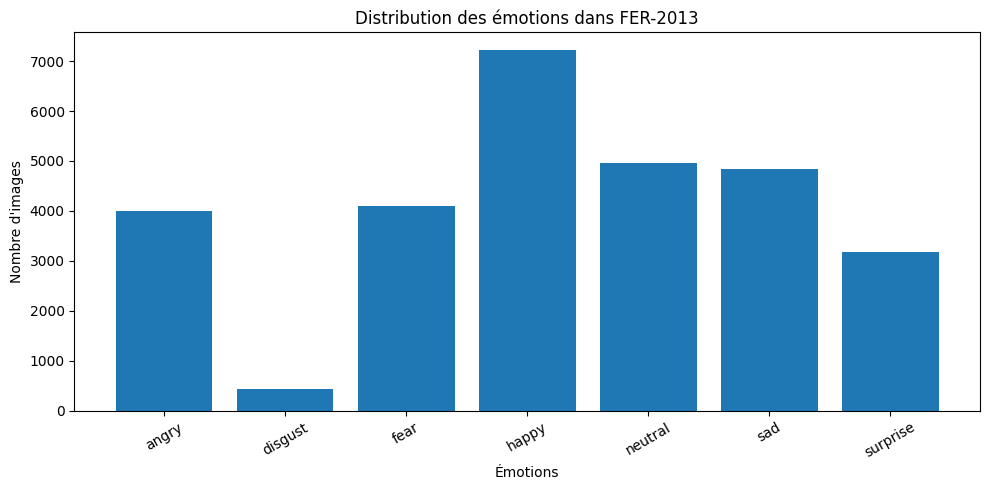

{'angry': 3995, 'disgust': 436, 'fear': 4097, 'happy': 7215, 'neutral': 4965, 'sad': 4830, 'surprise': 3171}


In [5]:
train_path = 'images_extraites/train'

emotion_counts = {}

for emotion in os.listdir(train_path):
    emotion_path = os.path.join(train_path, emotion)

    if os.path.isdir(emotion_path):
        emotion_counts[emotion] = len([
            f for f in os.listdir(emotion_path)
            if f.lower().endswith(('.jpg', '.jpeg', '.png'))
        ])

plt.figure(figsize=(10, 5))
plt.bar(emotion_counts.keys(), emotion_counts.values())
plt.title("Distribution des émotions dans FER-2013")
plt.xlabel("Émotions")
plt.ylabel("Nombre d'images")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

print(emotion_counts)


In [6]:
train_path = 'images_extraites/train'
test_path = 'images_extraites/test'

print("Nombre d'images par émotion :")

for dataset_name, path in [('Train', train_path), ('Test', test_path)]:
    print(f"\n{dataset_name} :")
    for emotion in sorted(os.listdir(path)):
        emotion_path = os.path.join(path, emotion)
        if os.path.isdir(emotion_path):
            images = [
                f for f in os.listdir(emotion_path)
                if f.lower().endswith(('.jpg', '.jpeg', '.png'))
            ]
            print(f"{emotion}: {len(images)} images")

# Vérifier les dimensions d'une image
emotion = os.listdir(train_path)[0]
image_name = os.listdir(os.path.join(train_path, emotion))[0]
image_path = os.path.join(train_path, emotion, image_name)

img = Image.open(image_path)
print("\nDimensions d'une image :", img.size)
print("Mode de l'image :", img.mode)

Nombre d'images par émotion :

Train :
angry: 3995 images
disgust: 436 images
fear: 4097 images
happy: 7215 images
neutral: 4965 images
sad: 4830 images
surprise: 3171 images

Test :
angry: 958 images
disgust: 111 images
fear: 1024 images
happy: 1774 images
neutral: 1233 images
sad: 1247 images
surprise: 831 images

Dimensions d'une image : (48, 48)
Mode de l'image : L


## Préparation des données

In [7]:
print("Version TensorFlow :", tf.__version__)
print("GPU détecté :", tf.config.list_physical_devices('GPU'))

IMG_SIZE = (48, 48)
BATCH_SIZE = 32
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    'images_extraites/train',
    validation_split=0.2,
    subset='training',
    seed=SEED,
    image_size=IMG_SIZE,
    color_mode='grayscale',
    batch_size=BATCH_SIZE,
    label_mode='int'
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    'images_extraites/train',
    validation_split=0.2,
    subset='validation',
    seed=SEED,
    image_size=IMG_SIZE,
    color_mode='grayscale',
    batch_size=BATCH_SIZE,
    label_mode='int'
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    'images_extraites/test',
    image_size=IMG_SIZE,
    color_mode='grayscale',
    batch_size=BATCH_SIZE,
    label_mode='int',
    shuffle=False
)

class_names = train_ds.class_names
print("Classes :", class_names)

Version TensorFlow : 2.21.0
GPU détecté : []
Found 28709 files belonging to 7 classes.
Using 22968 files for training.
Found 28709 files belonging to 7 classes.
Using 5741 files for validation.
Found 7178 files belonging to 7 classes.
Classes : ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']


In [8]:
normalization = tf.keras.layers.Rescaling(1./255)

train_ds = train_ds.map(
    lambda x, y: (normalization(x), y)
)
val_ds = val_ds.map(
    lambda x, y: (normalization(x), y)
)
test_ds = test_ds.map(
    lambda x, y: (normalization(x), y)
)

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

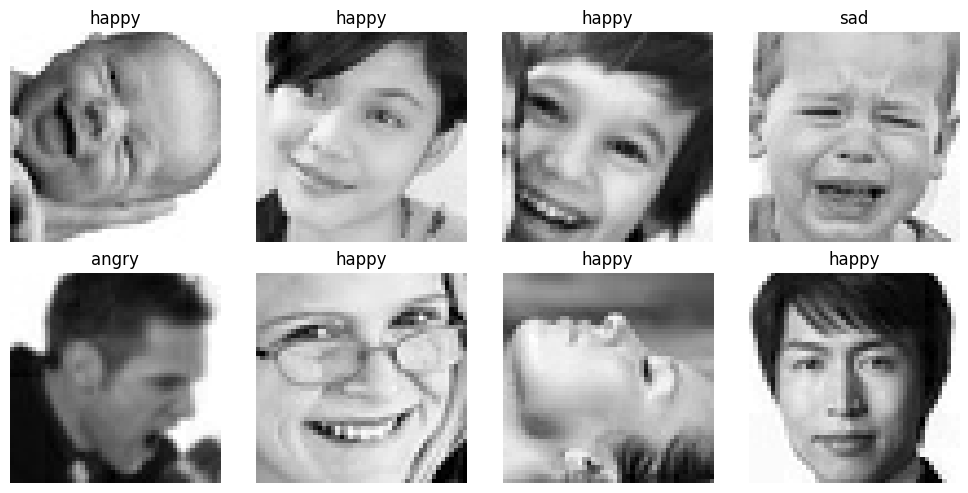

In [9]:
images, labels = next(iter(train_ds))

plt.figure(figsize=(10, 5))

for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(images[i].numpy().squeeze(), cmap='gray')
    plt.title(class_names[int(labels[i])])
    plt.axis('off')

plt.tight_layout()
plt.show()

In [10]:
y_train = np.concatenate([
    labels.numpy() for images, labels in train_ds
])

class_counts = np.bincount(y_train)

# Pondération adoucie pour éviter des poids trop extrêmes
weights = np.sqrt(
    len(y_train) / (len(class_counts) * class_counts)
)

# Normalisation des poids
weights = weights / np.mean(weights)

class_weights = {
    int(i): float(w)
    for i, w in enumerate(weights)
}

print("Classes :", class_names)
print("Effectifs :", class_counts)
print("Poids :", class_weights)

Classes : ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Effectifs : [3218  363 3285 5813 3965 3834 2490]
Poids : {0: 0.8078415646122331, 1: 2.4052814495610577, 2: 0.7995608618045258, 3: 0.6010616965881336, 4: 0.7277758137572091, 5: 0.7401046964404417, 6: 0.9183739172363998}


In [11]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.08)
])

## Construction du CNN de base

In [12]:
def build_baseline_cnn():

    inputs = layers.Input(shape=(48, 48, 1))

    x = data_augmentation(inputs)

    x = layers.Conv2D(32, 3, padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D()(x)

    x = layers.Conv2D(64, 3, padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D()(x)

    x = layers.Conv2D(128, 3, padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D()(x)

    x = layers.GlobalAveragePooling2D()(x)

    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.4)(x)

    outputs = layers.Dense(7, activation='softmax')(x)

    return Model(inputs, outputs)


baseline_model = build_baseline_cnn()

baseline_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

baseline_model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, 48, 48, 1)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ sequential (Sequential)              │ (None, 48, 48, 1)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d (Conv2D)                      │ (None, 48, 48, 32)          │             288 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 48, 48, 32)          │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation (Activation)              │ (None, 48, 48, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 24, 24, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 24, 24, 64)          │          18,432 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 24, 24, 64)          │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_1 (Activation)            │ (None, 24, 24, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 12, 12, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 12, 12, 128)         │          73,728 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 12, 12, 128)         │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_2 (Activation)            │ (None, 12, 12, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 6, 6, 128)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 128)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │          16,512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 7)                   │             903 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 110,759 (432.65 KB)

 Trainable params: 110,311 (430.90 KB)

 Non-trainable params: 448 (1.75 KB)

## Construction du CNN avec attention

In [13]:
def build_attention_cnn():

    inputs = layers.Input(shape=(48, 48, 1))

    x = data_augmentation(inputs)

    x = layers.Conv2D(32, 3, padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D()(x)

    x = layers.Conv2D(64, 3, padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D()(x)

    x = layers.Conv2D(128, 3, padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)

    # Attention spatiale
    attention = layers.Conv2D(
        1, 1, activation='sigmoid', padding='same'
    )(x)

    attended = layers.Multiply()([x, attention])

    # Connexion résiduelle
    x = layers.Add()([x, attended])

    x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)

    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.4)(x)

    outputs = layers.Dense(7, activation='softmax')(x)

    return Model(inputs, outputs)


attention_model = build_attention_cnn()

attention_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

attention_model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)    │ (None, 48, 48, 1)         │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ sequential (Sequential)       │ (None, 48, 48, 1)         │               0 │ input_layer_2[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_3 (Conv2D)             │ (None, 48, 48, 32)        │             288 │ sequential[1][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_3         │ (None, 48, 48, 32)        │             128 │ conv2d_3[0][0]             │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ activation_3 (Activation)     │ (None, 48, 48, 32)        │               0 │ batch_normalization_3[0][… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ max_pooling2d_3               │ (None, 24, 24, 32)        │               0 │ activation_3[0][0]         │
│ (MaxPooling2D)                │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_4 (Conv2D)             │ (None, 24, 24, 64)        │          18,432 │ max_pooling2d_3[0][0]      │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_4         │ (None, 24, 24, 64)        │             256 │ conv2d_4[0][0]             │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ activation_4 (Activation)     │ (None, 24, 24, 64)        │               0 │ batch_normalization_4[0][… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ max_pooling2d_4               │ (None, 12, 12, 64)        │               0 │ activation_4[0][0]         │
│ (MaxPooling2D)                │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_5 (Conv2D)             │ (None, 12, 12, 128)       │          73,728 │ max_pooling2d_4[0][0]      │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_5         │ (None, 12, 12, 128)       │             512 │ conv2d_5[0][0]             │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ activation_5 (Activation)     │ (None, 12, 12, 128)       │               0 │ batch_normalization_5[0][… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_6 (Conv2D)             │ (None, 12, 12, 1)         │             129 │ activation_5[0][0]         │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ multiply (Multiply)           │ (None, 12, 12, 128)       │               

 Total params: 110,888 (433.16 KB)

 Trainable params: 110,440 (431.41 KB)

 Non-trainable params: 448 (1.75 KB)

## Construction du Vision Transformer

In [14]:
# Configuration du Vision Transformer
IMG_SIZE = 48
PATCH_SIZE = 6
NUM_PATCHES = (IMG_SIZE // PATCH_SIZE) ** 2
PROJECTION_DIM = 64
NUM_HEADS = 4
NUM_TRANSFORMER_BLOCKS = 2
MLP_DIM = 128
NUM_CLASSES = 7


# Extraction des patches et projection
class PatchEmbedding(layers.Layer):
    def __init__(self, patch_size, projection_dim):
        super().__init__()
        self.projection = layers.Conv2D(
            filters=projection_dim,
            kernel_size=patch_size,
            strides=patch_size,
            padding="valid"
        )

    def call(self, images):
        x = self.projection(images)
        batch_size = tf.shape(x)[0]
        x = tf.reshape(
            x,
            [batch_size, NUM_PATCHES, PROJECTION_DIM]
        )
        return x


# Encodage positionnel
class PositionalEmbedding(layers.Layer):
    def __init__(self, num_patches, projection_dim):
        super().__init__()
        self.position_embedding = layers.Embedding(
            input_dim=num_patches,
            output_dim=projection_dim
        )
        self.positions = tf.range(start=0, limit=num_patches)

    def call(self, patches):
        positions = self.position_embedding(self.positions)
        return patches + positions


# Bloc Transformer
def transformer_block(x):
    # Multi-head self-attention
    attention_output = layers.MultiHeadAttention(
        num_heads=NUM_HEADS,
        key_dim=PROJECTION_DIM // NUM_HEADS,
        dropout=0.1
    )(x, x)

    x = layers.Add()([x, attention_output])
    x = layers.LayerNormalization(epsilon=1e-6)(x)

    # MLP
    mlp = layers.Dense(MLP_DIM, activation="gelu")(x)
    mlp = layers.Dropout(0.1)(mlp)
    mlp = layers.Dense(PROJECTION_DIM)(mlp)

    x = layers.Add()([x, mlp])
    x = layers.LayerNormalization(epsilon=1e-6)(x)

    return x


# Construction du modèle
def build_tiny_vit():

    inputs = layers.Input(shape=(48, 48, 1))

    x = data_augmentation(inputs)

    x = PatchEmbedding(
        PATCH_SIZE,
        PROJECTION_DIM
    )(x)

    x = PositionalEmbedding(
        NUM_PATCHES,
        PROJECTION_DIM
    )(x)

    for _ in range(NUM_TRANSFORMER_BLOCKS):
        x = transformer_block(x)

    x = layers.GlobalAveragePooling1D()(x)

    x = layers.Dense(128, activation="gelu")(x)
    x = layers.Dropout(0.3)(x)

    outputs = layers.Dense(
        NUM_CLASSES,
        activation="softmax"
    )(x)

    return Model(inputs, outputs, name="Tiny_ViT")


vit_model = build_tiny_vit()

vit_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

vit_model.summary()


Model: "Tiny_ViT"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)    │ (None, 48, 48, 1)         │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ sequential (Sequential)       │ (None, 48, 48, 1)         │               0 │ input_layer_3[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ patch_embedding               │ (None, 64, 64)            │           2,368 │ sequential[2][0]           │
│ (PatchEmbedding)              │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ positional_embedding          │ (None, 64, 64)            │           4,096 │ patch_embedding[0][0]      │
│ (PositionalEmbedding)         │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ multi_head_attention          │ (None, 64, 64)            │          16,640 │ positional_embedding[0][0… │
│ (MultiHeadAttention)          │                           │                 │ positional_embedding[0][0] │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ add_1 (Add)                   │ (None, 64, 64)            │               0 │ positional_embedding[0][0… │
│                               │                           │                 │ multi_head_attention[0][0] │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ layer_normalization           │ (None, 64, 64)            │             128 │ add_1[0][0]                │
│ (LayerNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_4 (Dense)               │ (None, 64, 128)           │           8,320 │ layer_normalization[0][0]  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dropout_3 (Dropout)           │ (None, 64, 128)           │               0 │ dense_4[0][0]              │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_5 (Dense)               │ (None, 64, 64)            │           8,256 │ dropout_3[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ add_2 (Add)                   │ (None, 64, 64)            │               0 │ layer_normalization[0][0], │
│                               │                           │                 │ dense_5[0][0]              │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ layer_normalization_1         │ (None, 64, 64)            │             128 │ add_2[0][0]                │
│ (LayerNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ multi_head_attention_1        │ (None, 64, 64)            │          16,640 │ layer_normalization_1[0][… │
│ (MultiHeadAttention)          │                           │                 │ layer_normalization_1[0][… │
├───────────────────────────────┼───────────────────────────┼───────────────

 Total params: 82,631 (322.78 KB)

 Trainable params: 82,631 (322.78 KB)

 Non-trainable params: 0 (0.00 B)

## Construction du CNN-APP-Transformer

In [15]:

# Configuration du modèle CNN-APP-Transformer
APP_FEATURE_DIM = 64
APP_NUM_PATCHES = 36       # feature map 6 x 6
APP_KEEP_RATIO = 0.75
APP_KEEP_K = int(APP_NUM_PATCHES * APP_KEEP_RATIO)  # 27 patches

APP_NUM_HEADS = 4
APP_NUM_BLOCKS = 2
APP_MLP_DIM = 128
APP_NUM_CLASSES = 7


# 1. Attentive Patch Pooling
class AttentivePatchPooling(layers.Layer):

    def __init__(self, keep_k=27, **kwargs):
        super().__init__(**kwargs)
        self.keep_k = keep_k

    def call(self, features):
        # features: (batch, height, width, channels)

        batch_size = tf.shape(features)[0]
        channels = tf.shape(features)[-1]

        # Transformer la carte de caractéristiques en patches
        patches = tf.reshape(
            features,
            [batch_size, -1, channels]
        )

        # Critère d'importance : somme des valeurs absolues
        importance = tf.reduce_sum(
            tf.abs(patches),
            axis=-1
        )

        # Sélection des K patches les plus importants
        top_values, top_indices = tf.math.top_k(
            importance,
            k=self.keep_k,
            sorted=True
        )

        selected_patches = tf.gather(
            patches,
            top_indices,
            axis=1,
            batch_dims=1
        )

        return selected_patches


# 2. Ajout du token de classification [CLS]
class AddClassToken(layers.Layer):

    def build(self, input_shape):
        self.cls_token = self.add_weight(
            name="cls_token",
            shape=(1, 1, input_shape[-1]),
            initializer="random_normal",
            trainable=True
        )

    def call(self, patches):
        batch_size = tf.shape(patches)[0]

        cls_tokens = tf.broadcast_to(
            self.cls_token,
            [batch_size, 1, tf.shape(patches)[-1]]
        )

        return tf.concat([cls_tokens, patches], axis=1)


# 3. Encodage positionnel
class APPPositionalEmbedding(layers.Layer):

    def __init__(self, sequence_length, projection_dim, **kwargs):
        super().__init__(**kwargs)
        self.position_embedding = layers.Embedding(
            input_dim=sequence_length,
            output_dim=projection_dim
        )
        self.sequence_length = sequence_length

    def call(self, tokens):
        positions = tf.range(
            start=0,
            limit=self.sequence_length
        )
        position_embeddings = self.position_embedding(positions)

        return tokens + position_embeddings


# 4. Bloc Transformer
def app_transformer_block(x):

    attention_output = layers.MultiHeadAttention(
        num_heads=APP_NUM_HEADS,
        key_dim=APP_FEATURE_DIM // APP_NUM_HEADS,
        dropout=0.1
    )(x, x)

    x = layers.Add()([x, attention_output])
    x = layers.LayerNormalization(epsilon=1e-6)(x)

    mlp = layers.Dense(
        APP_MLP_DIM,
        activation="gelu"
    )(x)

    mlp = layers.Dropout(0.1)(mlp)
    mlp = layers.Dense(APP_FEATURE_DIM)(mlp)

    x = layers.Add()([x, mlp])
    x = layers.LayerNormalization(epsilon=1e-6)(x)

    return x


# 5. Construction du modèle complet
def build_cnn_app_transformer():

    inputs = layers.Input(shape=(48, 48, 1))

    # Augmentation des données
    x = data_augmentation(inputs)

    # Backbone CNN léger
    x = layers.Conv2D(
        32, 3, padding="same", activation="relu"
    )(x)
    x = layers.MaxPooling2D()(x)  # 24 x 24

    x = layers.Conv2D(
        64, 3, padding="same", activation="relu"
    )(x)
    x = layers.MaxPooling2D()(x)  # 12 x 12

    x = layers.Conv2D(
        APP_FEATURE_DIM, 3, padding="same", activation="relu"
    )(x)
    x = layers.MaxPooling2D()(x)  # 6 x 6

    # APP : conserver les patches les plus informatifs
    x = AttentivePatchPooling(
        keep_k=APP_KEEP_K,
        name="attentive_patch_pooling"
    )(x)

    # Ajouter le token CLS
    x = AddClassToken()(x)

    # Encodage positionnel : 27 patches + 1 CLS
    x = APPPositionalEmbedding(
        sequence_length=APP_KEEP_K + 1,
        projection_dim=APP_FEATURE_DIM
    )(x)

    # Blocs Transformer
    for _ in range(APP_NUM_BLOCKS):
        x = app_transformer_block(x)

    # Classification à partir du token CLS
    x = layers.Lambda(lambda t: t[:, 0, :])(x)

    x = layers.Dense(128, activation="gelu")(x)
    x = layers.Dropout(0.3)(x)

    outputs = layers.Dense(
        APP_NUM_CLASSES,
        activation="softmax"
    )(x)

    return Model(
        inputs,
        outputs,
        name="CNN_APP_Transformer"
    )


app_vit_model = build_cnn_app_transformer()

app_vit_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0005
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

app_vit_model.summary()


Model: "CNN_APP_Transformer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)    │ (None, 48, 48, 1)         │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ sequential (Sequential)       │ (None, 48, 48, 1)         │               0 │ input_layer_4[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_8 (Conv2D)             │ (None, 48, 48, 32)        │             320 │ sequential[3][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ max_pooling2d_6               │ (None, 24, 24, 32)        │               0 │ conv2d_8[0][0]             │
│ (MaxPooling2D)                │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_9 (Conv2D)             │ (None, 24, 24, 64)        │          18,496 │ max_pooling2d_6[0][0]      │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ max_pooling2d_7               │ (None, 12, 12, 64)        │               0 │ conv2d_9[0][0]             │
│ (MaxPooling2D)                │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_10 (Conv2D)            │ (None, 12, 12, 64)        │          36,928 │ max_pooling2d_7[0][0]      │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ max_pooling2d_8               │ (None, 6, 6, 64)          │               0 │ conv2d_10[0][0]            │
│ (MaxPooling2D)                │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ attentive_patch_pooling       │ (None, 27, 64)            │               0 │ max_pooling2d_8[0][0]      │
│ (AttentivePatchPooling)       │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ add_class_token               │ (None, 28, 64)            │              64 │ attentive_patch_pooling[0… │
│ (AddClassToken)               │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ app_positional_embedding      │ (None, 28, 64)            │           1,792 │ add_class_token[0][0]      │
│ (APPPositionalEmbedding)      │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ multi_head_attention_2        │ (None, 28, 64)            │          16,640 │ app_positional_embedding[… │
│ (MultiHeadAttention)          │                           │                 │ app_positional_embedding[… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ add_5 (Add)                   │ (None, 28, 64)            │               0 │ app_positional_embedding[… │
│                               │                           │                 │ multi_head_attention_2[0]… │
├───────────────────────────────┼───────────────────────────┼───────────────

 Total params: 133,767 (522.53 KB)

 Trainable params: 133,767 (522.53 KB)

 Non-trainable params: 0 (0.00 B)

## Entraînement des modèles

In [16]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=3,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=2,
        min_lr=0.00001,
        verbose=1
    )
]

### Entraînement du CNN de base

In [17]:
history_baseline = baseline_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks,
    class_weight=class_weights
)

Epoch 1/10


E:\python-calnum\env-calnum\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


718/718 ━━━━━━━━━━━━━━━━━━━━ 59s 74ms/step - accuracy: 0.2434 - loss: 1.4393 - val_accuracy: 0.2303 - val_loss: 1.8003 - learning_rate: 5.0000e-04
Epoch 2/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 49s 68ms/step - accuracy: 0.2857 - loss: 1.3917 - val_accuracy: 0.2601 - val_loss: 1.9633 - learning_rate: 5.0000e-04
Epoch 3/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 49s 68ms/step - accuracy: 0.3222 - loss: 1.3463 - val_accuracy: 0.2904 - val_loss: 1.7018 - learning_rate: 5.0000e-04
Epoch 4/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 49s 68ms/step - accuracy: 0.3500 - loss: 1.3057 - val_accuracy: 0.3165 - val_loss: 1.8343 - learning_rate: 5.0000e-04
Epoch 5/10
717/718 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.3749 - loss: 1.2780
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
718/718 ━━━━━━━━━━━━━━━━━━━━ 50s 70ms/step - accuracy: 0.3750 - loss: 1.2780 - val_accuracy: 0.2442 - val_loss: 1.7177 - learning_rate: 5.0000e-04
Epoch 6/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 49s 68ms/step - accuracy: 0.3

### Entraînement du CNN avec attention

In [18]:
history_attention = attention_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks,
    class_weight=class_weights
)

Epoch 1/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 54s 71ms/step - accuracy: 0.2401 - loss: 1.4455 - val_accuracy: 0.1758 - val_loss: 2.0130 - learning_rate: 5.0000e-04
Epoch 2/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 51s 71ms/step - accuracy: 0.2922 - loss: 1.3815 - val_accuracy: 0.2142 - val_loss: 2.0591 - learning_rate: 5.0000e-04
Epoch 3/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 51s 72ms/step - accuracy: 0.3308 - loss: 1.3299 - val_accuracy: 0.3510 - val_loss: 1.6114 - learning_rate: 5.0000e-04
Epoch 4/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 51s 71ms/step - accuracy: 0.3652 - loss: 1.2880 - val_accuracy: 0.2961 - val_loss: 1.7228 - learning_rate: 5.0000e-04
Epoch 5/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 52s 72ms/step - accuracy: 0.3875 - loss: 1.2540 - val_accuracy: 0.3813 - val_loss: 1.5832 - learning_rate: 5.0000e-04
Epoch 6/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 51s 71ms/step - accuracy: 0.4112 - loss: 1.2231 - val_accuracy: 0.4111 - val_loss: 1.4808 - learning_rate: 5.0000e-04
Epoch 7/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 54s 74ms/ste

### Entraînement du Vision Transformer

In [19]:
history_vit = vit_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    class_weight=class_weights,
    callbacks=callbacks
)


Epoch 1/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 44s 52ms/step - accuracy: 0.2146 - loss: 1.4549 - val_accuracy: 0.2223 - val_loss: 1.8046 - learning_rate: 5.0000e-04
Epoch 2/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 38s 53ms/step - accuracy: 0.2475 - loss: 1.4260 - val_accuracy: 0.2778 - val_loss: 1.7758 - learning_rate: 5.0000e-04
Epoch 3/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 37s 51ms/step - accuracy: 0.2863 - loss: 1.4009 - val_accuracy: 0.3097 - val_loss: 1.7459 - learning_rate: 5.0000e-04
Epoch 4/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 36s 50ms/step - accuracy: 0.3027 - loss: 1.3771 - val_accuracy: 0.3384 - val_loss: 1.6846 - learning_rate: 5.0000e-04
Epoch 5/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 37s 51ms/step - accuracy: 0.3204 - loss: 1.3596 - val_accuracy: 0.3487 - val_loss: 1.6700 - learning_rate: 5.0000e-04
Epoch 6/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 36s 50ms/step - accuracy: 0.3290 - loss: 1.3484 - val_accuracy: 0.3419 - val_loss: 1.6689 - learning_rate: 5.0000e-04
Epoch 7/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 37s 51ms/ste

### Entraînement du CNN_APP_Transformer

In [ ]:
history_app_vit = app_vit_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    class_weight=class_weights,
    callbacks=callbacks
)


## Évaluation et comparaison des modèles

In [ ]:

y_true = np.concatenate([
    labels.numpy()
    for images, labels in test_ds
])

# Les quatre modèles
models = {
    "CNN Baseline": baseline_model,
    "CNN Attention": attention_model,
    "Tiny ViT": vit_model,
    "CNN-APP-Transformer": app_vit_model
}


class_results = []

for model_name, model in models.items():


    # Prédictions
    probabilities = model.predict(test_ds, verbose=0)
    y_pred = np.argmax(probabilities, axis=1)

    # Métriques globales
    accuracy = accuracy_score(y_true, y_pred)

    macro_f1 = f1_score(
        y_true, y_pred,
        average="macro",
        zero_division=0
    )

    weighted_f1 = f1_score(
        y_true, y_pred,
        average="weighted",
        zero_division=0
    )


    # Rapport par émotion
    report = classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        output_dict=True,
        zero_division=0
    )

    for emotion in class_names:
        class_results.append({
            "Model": model_name,
            "Emotion": emotion,
            "Precision": report[emotion]["precision"],
            "Recall": report[emotion]["recall"],
            "F1-score": report[emotion]["f1-score"]
        })
def evaluate_model(model, name):

    y_true = np.concatenate([
        labels.numpy() for images, labels in test_ds
    ])

    probabilities = model.predict(test_ds)
    y_pred = np.argmax(probabilities, axis=1)

    print("\n", name)
    print(classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        zero_division=0
    ))
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro F1": f1_score(
            y_true, y_pred, average='macro'
        ),
        "Weighted F1": f1_score(
            y_true, y_pred, average='weighted'
        )
    }
results = pd.DataFrame([
    evaluate_model(baseline_model, "CNN baseline"),
    evaluate_model(attention_model, "CNN attention"),
    evaluate_model(vit_model, "Tiny vit"),
    evaluate_model(app_vit_model, "CNN App Transformer")
])

display(results)


# Tableau par classe
class_df = pd.DataFrame(class_results)

print("\nCOMPARAISON PAR ÉMOTION")
display(
    class_df.pivot(
        index="Emotion",
        columns="Model",
        values="F1-score"
    ).style.format("{:.3f}")
)



## Visualisation comparative

In [ ]:

metrics = ["Accuracy", "Macro F1", "Weighted F1"]

ax = results.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(12, 6)
)

ax.set_title("Comparaison des quatre modèles")
ax.set_ylabel("Score")
ax.set_xlabel("Modèle")
ax.set_ylim(0, 1)
ax.legend(loc="lower right")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


In [ ]:

class_pivot = class_df.pivot(
    index="Emotion",
    columns="Model",
    values="F1-score"
)

ax = class_pivot.plot(
    kind="bar",
    figsize=(13, 6)
)

ax.set_title("Per-Class F1-score Comparison")
ax.set_ylabel("F1-score")
ax.set_xlabel("Emotion")
ax.set_ylim(0, 1)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


In [ ]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history_baseline.history['val_accuracy'],
         label='CNN base')
plt.plot(history_attention.history['val_accuracy'],
         label='CNN attention')
plt.plot(history_vit.history['val_accuracy'],
         label='Tiny vit')
plt.plot(history_app_vit.history['val_accuracy'],
         label='CNN app vit')
plt.title("Accuracy de validation")
plt.xlabel("Époques")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_baseline.history['val_loss'],
         label='CNN base')
plt.plot(history_attention.history['val_loss'],
         label='CNN attention')
plt.plot(history_vit.history['val_loss'],
         label='Tiny vit')
plt.plot(history_app_vit.history['val_loss'],
         label='CNN app vit')
plt.title("Loss de validation")
plt.xlabel("Époques")
plt.legend()

plt.tight_layout()
plt.show()

## Sauvegarde des modèles

In [ ]:
baseline_model.save('cnn_baseline.keras')
attention_model.save('cnn_attention.keras')
vit_model.save('tiny_vit.keras')
app_vit_model.save('app_vit.keras')

print("Les quatre modèles ont été sauvegardés.")